# Likevektsarealkriteriet - Equal Area Criterion

Likevektsaralkriteriet, bedre kjent som Equal Area Criterion (EAC), heretter EAC, er en grafisk metode som gjør det mulig å avgjøre transient stabilitet for et system modellert som SMIB, utifra et simplet kriterie uten å løse komplekse svingeligninger numerisk.
EAC avgjør om et system klarer å hente seg inn etter en større forstyrrelse, førstesvingstabilitet, og bevare synkronismen. Klarer ikke systemet å hente seg inn etter første sving, er systemet ustabilt og generatoren faller ut av synkronisme. 

## Svingeligningen

Vi betrakter svingeligningen.

$$
M \frac{d^2\delta}{dt^2} = Pa
$$

Vi vet at $M = \frac{H}{\pi f} \quad \text{ved per unit}$

$$
\frac{H}{\pi f} \frac{d^2\delta}{dt^2} = Pa
$$

Siden H, og f er konstanter, ser vi på når den (andre)deriverte av rotorvinkelen er null.
Fra dette definerer vi følgende kriterie for stabilitet;
Systemet er stabilt hvis over tid (1 sekund er tilstrekkelig):

$$ \frac{d\delta}{dt} = 0$$

og ustabilt om:

$$ \frac{d\delta}{dt} > 0$$

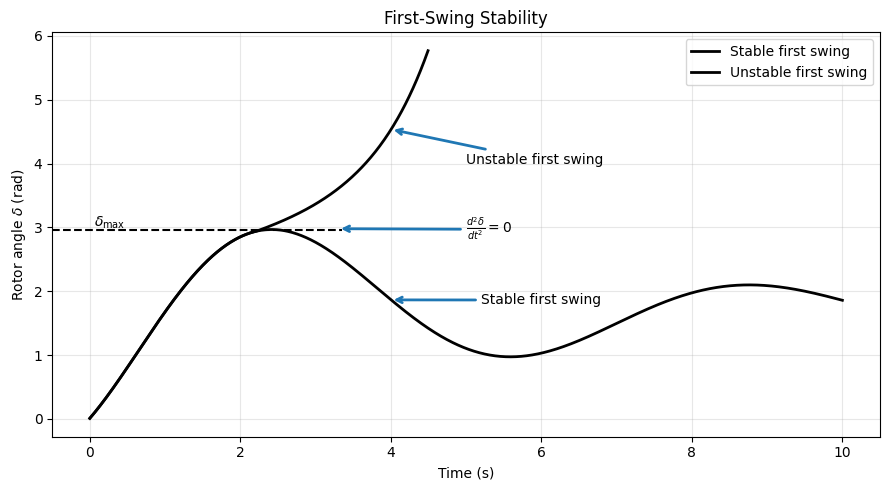

In [66]:
# TEST CELL
import numpy as np
import matplotlib.pyplot as plt

# Tid
t = np.linspace(0, 10, 1000)

# Felles startverdi
delta0 = 0.01

# Stable first swing
delta_stable = (
    1.0
    + 2*np.exp(-0.18*t)*np.sin(0.99*t - 1)
)
delta_stable += delta0 - delta_stable[0]

# Ustabil first swing:
# følger stabil kurve til toppunktet
idx_max = np.argmax(delta_stable)
t_sep = t[idx_max] - 0.2

idx_sep = np.argmin(np.abs(t - t_sep))
delta_sep = delta_stable[idx_sep]
slope_sep = np.gradient(delta_stable, t)[idx_sep]

delta_unstable = delta_stable.copy()

mask = t > t_sep
tau = t[mask] - t_sep

delta_unstable[mask] = (
    delta_sep
    + slope_sep*tau
    + 0.12*(np.exp(1.3*tau)-1)
)

# Figur
fig, ax = plt.subplots(figsize=(9,5))

ax.plot(t, delta_stable,
        lw=2,
        color='black',
        label='Stable first swing')

ax.plot(t[t <= 4.5],
        delta_unstable[t <= 4.5],
        lw=2,
        color='black',
        label='Unstable first swing')

# Maksimum på stabil kurve
delta_max = np.max(delta_stable)

ax.axhline(delta_max,
           xmax=0.35,
           color='k',
           ls='--')

ax.text(0.05,
        delta_max+0.05,
        r'$\delta_{\max}$')

# Annotasjoner
ax.annotate('Stable first swing',
            xy=(4.0,
                delta_stable[np.argmin(abs(t-4.0))]),
            xytext=(5.2,1.8),
            arrowprops=dict(
                arrowstyle='->',
                color='tab:blue',
                lw=2))

ax.annotate('Unstable first swing',
            xy=(4,
                delta_unstable[np.argmin(abs(t-4))]),
            xytext=(5,4.0),
            arrowprops=dict(
                arrowstyle='->',
                color='tab:blue',
                lw=2))

ax.annotate(r'$\frac{d^2\delta}{dt^2}=0$',
            xy=(3.3,
                delta_unstable[np.argmin(abs(t-2.3))]),
            xytext=(5,2.9),
            arrowprops=dict(
                arrowstyle='->',
                color='tab:blue',
                lw=2))
# Akser
ax.set_xlabel('Time (s)')
ax.set_ylabel(r'Rotor angle $\delta$ (rad)')
ax.set_title('First-Swing Stability')

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## Modifiserer svingeligningen

Vi tar utgangspunkt i svingeligningen for å omgjøre den til en enkel applikerbar form til å avgjøre stabilitet.

$$
\frac{H}{\pi f} \frac{d^2\delta}{dt^2} = Pa
$$

og ser på $\frac{d^2\delta}{dt^2}$:

$$
\frac{d^2\delta}{dt^2} = \frac{\pi f}{H} P_a
$$

Vi multipliserer begge sider med $\big(2\frac{d\delta}{dt}\big)$:

$$
\big(2\frac{d\delta}{dt}\big)\frac{d^2\delta}{dt^2} = \big(2\frac{d\delta}{dt}\big)\frac{\pi f}{H} P_a
$$

Gjenkjenner kjerneregelen når u er satt til $\frac{d\delta}{dt}$

$$
\frac{d}{dt}\bigg(\bigg[\frac{d\delta}{dt}\bigg]^2\bigg) = \big(2\frac{d\delta}{dt}\big)\frac{\pi f}{H} P_a
$$

Gnager med dt på hver side:

$$
\frac{d}{dt}\bigg(\bigg[\frac{d\delta}{dt}\bigg]^2\bigg)\cdot dt = \big(2\frac{d\delta}{dt}\big)\cdot dt\frac{\pi f}{H} P_a
$$

Integrerer

$$
\bigg(\frac{d\delta}{dt}^2\bigg) = \frac{2\pi f}{H}\int_{\delta_0}^{\delta_{max}} P_a d\delta
$$

eller

$$
\frac{d\delta}{dt} = \sqrt{\frac{2\pi f}{H}\int_{\delta_0}^{\delta_{max}} P_a d\delta}
$$

## Evalueres ved 0

Evaluerer uttrykket ved 0

$$
 \sqrt{\frac{2\pi f}{H}\int_{\delta_0}^{\delta_{max}} P_a d\delta} = 0
$$

eller integralet

$$
\int_{\delta_0}^{\delta_{max}} P_a d\delta = 0
$$

### Likearealkriteriet

Stabilitetsbetingelsen kan uttrykkes slik: Systemet er stabilt dersom arealet under kurven for akselererende effekt $P_a$ som funksjon av rotorvinkelen $\delta$ blir null ved en bestemt verdi av $\delta$.

Med andre ord må det positive arealet (akselerasjonsarealet) være lik det negative arealet (deakselerasjonsarealet). Derfor kalles dette **likearealkriteriet** (*equal area criterion*) for stabilitet.

Etter en forstyrrelse vil generatoren først akselerere slik at rotorvinkelen $\delta$ øker. Arealet

$$
A_1 = \int P_a \, d\delta
$$

representerer den kinetiske energien som lagres i rotoren under akselerasjonen.

For at systemet skal forbli stabilt, må denne energien senere fjernes gjennom en periode med negativ akselererende effekt ($P_a < 0$). Dette gir et deakselerasjonsareal

$$
A_2 = \int (-P_a)\, d\delta .
$$

Første sving er stabil dersom

$$
A_1 = A_2 .
$$



Når de to arealene er like store, blir rotorhastigheten igjen lik synkronhastigheten, og maskinen forblir i synkronisme med nettet.

Likt areal-kriteriet kan derfor oppsummeres som

$$
\int_{\delta_0}^{\delta_c} P_a \, d\delta
=
\int_{\delta_c}^{\delta_{\max}} (-P_a)\, d\delta ,
$$

eller ekvivalent

$$
\int_{\delta_0}^{\delta_{\max}} P_a \, d\delta = 0.
$$

Dette er grunnlaget for **likearealkriteriet** (*equal area criterion*) ved analyse av transient stabilitet.

δ0     = 30.00°
δcr    = 79.56°
δmax   = 150.00°
A1     = 0.432510
A2     = 0.432510


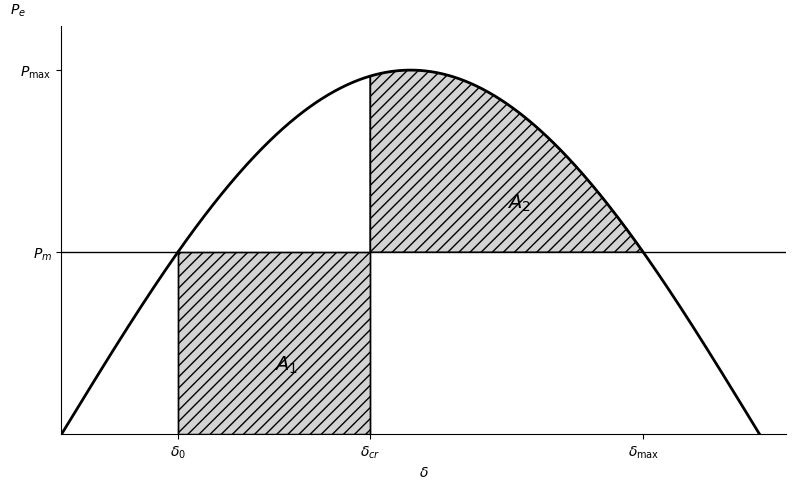

In [3]:
# TEST CELL
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# System parameters
# --------------------------------------------------
Pmax = 1.0

# Initial operating point
delta0 = np.radians(30)
Pm = Pmax * np.sin(delta0)

# Maximum excursion angle
delta_max = np.pi - delta0

# Critical clearing angle from equal-area criterion
delta_cr = np.arccos(
    (delta_max - delta0) * np.sin(delta0)
    + np.cos(delta_max)
)

# --------------------------------------------------
# Verify equal areas
# --------------------------------------------------
A1 = Pm * (delta_cr - delta0)

d2_int = np.linspace(delta_cr, delta_max, 5000)
A2 = np.trapezoid(Pmax * np.sin(d2_int) - Pm, d2_int)

print(f"δ0     = {np.degrees(delta0):.2f}°")
print(f"δcr    = {np.degrees(delta_cr):.2f}°")
print(f"δmax   = {np.degrees(delta_max):.2f}°")
print(f"A1     = {A1:.6f}")
print(f"A2     = {A2:.6f}")

# --------------------------------------------------
# Plot
# --------------------------------------------------
delta = np.linspace(0, np.pi, 1000)
Pe = Pmax * np.sin(delta)

fig, ax = plt.subplots(figsize=(8, 5))

# Power-angle curve
ax.plot(delta, Pe, color='black', lw=2)

# Mechanical power line
ax.axhline(Pm, color='black', lw=1)

# A1 region
d1 = np.linspace(delta0, delta_cr, 500)
ax.fill_between(
    d1, 0, Pm,
    facecolor='lightgray',
    hatch='///',
    edgecolor='black'
)

# A2 region
d2 = np.linspace(delta_cr, delta_max, 500)
ax.fill_between(
    d2,
    Pm,
    Pmax * np.sin(d2),
    facecolor='lightgray',
    hatch='///',
    edgecolor='black'
)

# Vertical lines
ax.vlines(delta0, 0, Pm, color='black', lw=1)
ax.vlines(delta_cr, 0, Pmax*np.sin(delta_cr), color='black', lw=1)

# Labels inside areas
ax.text(
    (delta0 + delta_cr)/2,
    0.35*Pm,
    r'$A_1$',
    fontsize=14
)

ax.text(
    (delta_cr + delta_max)/2,
    Pm + 0.12,
    r'$A_2$',
    fontsize=14
)

# Axis labels
ax.set_xticks([delta0, delta_cr, delta_max])
ax.set_xticklabels([
    r'$\delta_0$',
    r'$\delta_{cr}$',
    r'$\delta_{\max}$'
])

ax.set_yticks([Pm, Pmax])
ax.set_yticklabels([
    r'$P_m$',
    r'$P_{\max}$'
])

ax.set_xlim(0, np.pi + 0.12)
ax.set_ylim(0, 1.12)

# Clean textbook style
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xlabel(r'$\delta$')
ax.set_ylabel(r'$P_e$', rotation=0)
ax.yaxis.set_label_coords(-0.06, 1.02)

plt.tight_layout()
plt.show()

## Utledning av kritisk utkoblingsvinkel

Akselerasjonsarealet er

$$
A_1
=
\int_{\delta_0}^{\delta_{cr}} P_m \, d\delta
=
P_m(\delta_{cr}-\delta_0)
$$

Retardasjonsarealet er

$$
A_2
=
\int_{\delta_{cr}}^{\delta_{\max}}
\left(P_{\max}\sin\delta-P_m\right)d\delta
$$

Integrerer leddvis:

$$
A_2
=
P_{\max}\int_{\delta_{cr}}^{\delta_{\max}}
\sin\delta \, d\delta
-
P_m\int_{\delta_{cr}}^{\delta_{\max}} d\delta
$$


For første integral:

$$
\int \sin\delta\,d\delta
=
-\cos\delta
$$

slik at

$$
P_{\max}
\Big[-\cos\delta\Big]_{\delta_{cr}}^{\delta_{\max}}
=
P_{\max}
\left(
\cos\delta_{cr}
-
\cos\delta_{\max}
\right)
$$

For det andre integralet:

$$
\int d\delta
=
\delta
$$

slik at

$$
P_m
\Big[\delta\Big]_{\delta_{cr}}^{\delta_{\max}}
=
P_m
\left(
\delta_{\max}
-
\delta_{cr}
\right)
$$

Dermed blir

$$
A_2
=
P_{\max}
\left(
\cos\delta_{cr}
-
\cos\delta_{\max}
\right)
-
P_m
\left(
\delta_{\max}
-
\delta_{cr}
\right)
$$

Likearealkriteriet krever at

$$
A_1=A_2.
$$

Setter inn uttrykkene for $A_1$ og $A_2$:

$$
P_m(\delta_{cr}-\delta_0)
=
P_{\max}
\left(
\cos\delta_{cr}
-
\cos\delta_{\max}
\right)
-
P_m
\left(
\delta_{\max}
-
\delta_{cr}
\right)
$$

Utvider høyresiden:

$$
P_m\delta_{cr}
-
P_m\delta_0
=
P_{\max}
\left(
\cos\delta_{cr}
-
\cos\delta_{\max}
\right)
-
P_m\delta_{\max}
+
P_m\delta_{cr}
$$



Leddet $P_m\delta_{cr}$ finnes på begge sider og kanselleres:

$$
-P_m\delta_0
=
P_{\max}
\left(
\cos\delta_{cr}
-
\cos\delta_{\max}
\right)
-
P_m\delta_{\max}
$$

Flytter $P_m\delta_{\max}$ til venstre:

$$
P_m
\left(
\delta_{\max}
-
\delta_0
\right)
=
P_{\max}
\left(
\cos\delta_{cr}
-
\cos\delta_{\max}
\right)
$$

Dividerer med $P_{\max}$:

$$
\frac{P_m}{P_{\max}}
\left(
\delta_{\max}
-
\delta_0
\right)
=
\cos\delta_{cr}
-
\cos\delta_{\max}
$$

og løser for $\cos\delta_{cr}$:

$$
\boxed{
\cos\delta_{cr}
=
\frac{P_m}{P_{\max}}
\left(
\delta_{\max}
-
\delta_0
\right)
+
\cos\delta_{\max}
}
$$


For tilfellet med en terminalkortslutning hvor

$$
P_e=0
$$

under feilen, er

$$
P_m=P_{\max}\sin\delta_0
$$

og

$$
\delta_{\max}
=
\pi-\delta_0.
$$


Setter vi dette inn, får vi

$$
\cos\delta_{cr}
=
\sin\delta_0
\left(
\pi-2\delta_0
\right)
-
\cos\delta_0
$$

slik at

$$
\boxed{
\delta_{cr}
=
\cos^{-1}
\left[
(\pi-2\delta_0)\sin\delta_0
-
\cos\delta_0
\right]
}
$$

Alle vinkler i denne formelen må uttrykkes i **radianer**.

## Kritisk utkoblingstid

Svingligningen kan skrives som

$$
\frac{H}{\pi f}
\frac{d^2\delta}{dt^2}
=
P_m.
$$

Dermed blir akselerasjonen konstant:

$$
\frac{d^2\delta}{dt^2}
=
\frac{\pi f}{H}P_m.
$$

Integrasjon med

$$
\left.\frac{d\delta}{dt}\right|_{t=0}=0
$$

gir

$$
\delta(t)
=
\delta_0
+
\frac{1}{2}
\frac{\pi f}{H}
P_m t^2.
$$

Når

$$
\delta=\delta_{cr},
$$

oppnås den kritiske utkoblingstiden

$$
\boxed{
t_{cr}
=
\sqrt{
\frac{2H}{\pi f P_m}
(\delta_{cr}-\delta_0)
}
}
$$

hvor alle vinkler må uttrykkes i radianer.



In [4]:
import numpy as np

def critical_clearing(Pm, Pmax, H, f=50):
    """
    Kritisk utkoblingsvinkel og kritisk utkoblingstid
    for tilfellet Pe = 0 under feilen.
    """

    delta0 = np.arcsin(Pm / Pmax)

    delta_cr = np.arccos(
        (np.pi - 2 * delta0) * np.sin(delta0)
        - np.cos(delta0)
    )

    t_cr = np.sqrt(
        (2 * H / (np.pi * f * Pm))
        * (delta_cr - delta0)
    )

    return delta0, delta_cr, t_cr

In [5]:
# Eksempel
delta0, delta_cr, t_cr = critical_clearing(
    Pm=1.0,
    Pmax=2.10,
    H=5.0,
    f=50
)

print(f"δ0  = {np.degrees(delta0):.2f}°")
print(f"δcr = {np.degrees(delta_cr):.2f}°")
print(f"tcr = {t_cr:.4f} s")

δ0  = 28.44°
δcr = 81.72°
tcr = 0.2433 s


# Likearealkriteriet for en ikke-null feilkurve

Dette er utledningen av likearealkriteriet for en ikke-null feilkurve $P_{e,II}$, i motsetning til det tidligere tilfellet hvor $P_e=0$ under feilen.

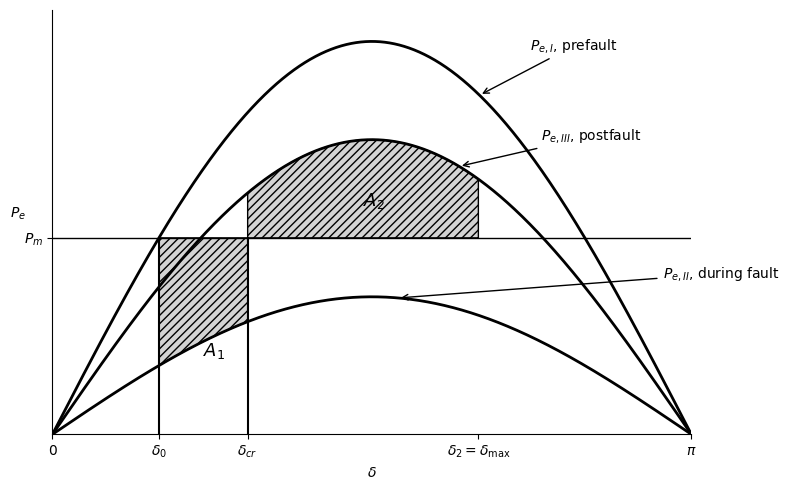

In [30]:
# TEST CELL
import numpy as np
import matplotlib.pyplot as plt

# Power-angle axis
delta = np.linspace(0, np.pi, 2000)

# Curves
Pmax_I   = 1.00   # prefault
Pmax_II  = 0.35   # during fault
Pmax_III = 0.75   # postfault

# Operating point
delta0 = np.radians(30)
Pm = Pmax_I * np.sin(delta0)

# Angles chosen for a textbook-like figure
delta_cr  = np.radians(55)
delta_max = np.radians(120)

# Power-angle curves
Pe_I   = Pmax_I   * np.sin(delta)
Pe_II  = Pmax_II  * np.sin(delta)
Pe_III = Pmax_III * np.sin(delta)

fig, ax = plt.subplots(figsize=(8,5))

# Prefault (double line)
ax.plot(delta, Pe_I, 'k', lw=2)

# Postfault
ax.plot(delta, Pe_III, 'k', lw=2)

# During fault
ax.plot(delta, Pe_II, 'k', lw=2)

# Mechanical power
ax.axhline(Pm, color='k', lw=1)

# A1
dA1 = np.linspace(delta0, delta_cr, 500)
ax.fill_between(
    dA1,
    Pmax_II*np.sin(dA1),
    Pm,
    hatch='////',
    facecolor='lightgray',
    edgecolor='k'
)

# A2
dA2 = np.linspace(delta_cr, delta_max, 500)
ax.fill_between(
    dA2,
    Pm,
    Pmax_III*np.sin(dA2),
    hatch='////',
    facecolor='lightgray',
    edgecolor='k'
)

# Vertical lines
ax.vlines(delta0, 0, Pm, colors='k')
ax.vlines(delta_cr, 0, Pm, colors='k')

# Labels
ax.text((delta0+delta_cr)/2, 0.4*Pm, r'$A_1$', fontsize=13)
ax.text((delta_cr+delta_max)/2, Pm+0.08, r'$A_2$', fontsize=13)

#ax.text(2.0, 0.98, r'$P_{e,I}$, prefault', fontsize=10)
#ax.text(2.05, 0.62, r'$P_{e,III}$, postfault', fontsize=10)
#ax.text(1.9, 0.23, r'$P_{e,II}$, during fault', fontsize=10)


# Postfault label with arrow
ax.annotate(
    r'$P_{e,I}$, prefault',
    xy=(2.1, Pmax_I*np.sin(2.1)),
    xytext=(2.35, 0.98),
    arrowprops=dict(arrowstyle='->', lw=1),
    fontsize=10
)
ax.annotate(
    r'$P_{e,III}$, postfault',
    xy=(2.0, Pmax_III*np.sin(2.0)),  # point on curve
    xytext=(2.4, 0.75),             # text location
    arrowprops=dict(arrowstyle='->', lw=1),
    fontsize=10
)



ax.annotate(
    r'$P_{e,II}$, during fault',
    xy=(1.7, Pmax_II*np.sin(1.7)),
    xytext=(3, 0.4),
    arrowprops=dict(arrowstyle='->', lw=1),
    fontsize=10
)

# Axes
ax.set_xticks([0, delta0, delta_cr, delta_max, np.pi])
ax.set_xticklabels([
    '0',
    r'$\delta_0$',
    r'$\delta_{cr}$',
    r'$\delta_2=\delta_{\max}$',
    r'$\pi$'
])

ax.set_yticks([Pm])
ax.set_yticklabels([r'$P_m$'])

ax.set_xlim(0, np.pi)
ax.set_ylim(0, 1.08)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xlabel(r'$\delta$')
ax.set_ylabel(r'$P_e$', rotation=0)

plt.tight_layout()
plt.show()

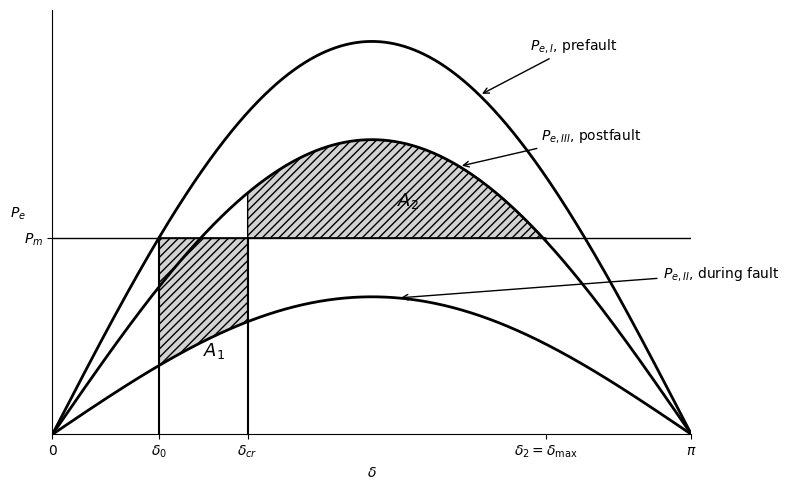

In [31]:
# TEST CELL
import numpy as np
import matplotlib.pyplot as plt

# Power-angle axis
delta = np.linspace(0, np.pi, 2000)

# Curves
Pmax_I   = 1.00   # prefault
Pmax_II  = 0.35   # during fault
Pmax_III = 0.75   # postfault

# Operating point
delta0 = np.radians(30)
Pm = Pmax_I * np.sin(delta0)

# Angles chosen for a textbook-like figure
delta_cr  = np.radians(55)
delta_max = np.radians(139)

# Power-angle curves
Pe_I   = Pmax_I   * np.sin(delta)
Pe_II  = Pmax_II  * np.sin(delta)
Pe_III = Pmax_III * np.sin(delta)

fig, ax = plt.subplots(figsize=(8,5))

# Prefault (double line)
ax.plot(delta, Pe_I, 'k', lw=2)

# Postfault
ax.plot(delta, Pe_III, 'k', lw=2)

# During fault
ax.plot(delta, Pe_II, 'k', lw=2)

# Mechanical power
ax.axhline(Pm, color='k', lw=1)

# A1
dA1 = np.linspace(delta0, delta_cr, 500)
ax.fill_between(
    dA1,
    Pmax_II*np.sin(dA1),
    Pm,
    hatch='////',
    facecolor='lightgray',
    edgecolor='k'
)

# A2
dA2 = np.linspace(delta_cr, delta_max, 500)
ax.fill_between(
    dA2,
    Pm,
    Pmax_III*np.sin(dA2),
    hatch='////',
    facecolor='lightgray',
    edgecolor='k'
)

# Vertical lines
ax.vlines(delta0, 0, Pm, colors='k')
ax.vlines(delta_cr, 0, Pm, colors='k')

# Labels
ax.text((delta0+delta_cr)/2, 0.4*Pm, r'$A_1$', fontsize=13)
ax.text((delta_cr+delta_max)/2, Pm+0.08, r'$A_2$', fontsize=13)

#ax.text(2.0, 0.98, r'$P_{e,I}$, prefault', fontsize=10)
#ax.text(2.05, 0.62, r'$P_{e,III}$, postfault', fontsize=10)
#ax.text(1.9, 0.23, r'$P_{e,II}$, during fault', fontsize=10)


# Postfault label with arrow
ax.annotate(
    r'$P_{e,I}$, prefault',
    xy=(2.1, Pmax_I*np.sin(2.1)),
    xytext=(2.35, 0.98),
    arrowprops=dict(arrowstyle='->', lw=1),
    fontsize=10
)
ax.annotate(
    r'$P_{e,III}$, postfault',
    xy=(2.0, Pmax_III*np.sin(2.0)),  # point on curve
    xytext=(2.4, 0.75),             # text location
    arrowprops=dict(arrowstyle='->', lw=1),
    fontsize=10
)



ax.annotate(
    r'$P_{e,II}$, during fault',
    xy=(1.7, Pmax_II*np.sin(1.7)),
    xytext=(3, 0.4),
    arrowprops=dict(arrowstyle='->', lw=1),
    fontsize=10
)

# Axes
ax.set_xticks([0, delta0, delta_cr, delta_max, np.pi])
ax.set_xticklabels([
    '0',
    r'$\delta_0$',
    r'$\delta_{cr}$',
    r'$\delta_2=\delta_{\max}$',
    r'$\pi$'
])

ax.set_yticks([Pm])
ax.set_yticklabels([r'$P_m$'])

ax.set_xlim(0, np.pi)
ax.set_ylim(0, 1.08)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_xlabel(r'$\delta$')
ax.set_ylabel(r'$P_e$', rotation=0)

plt.tight_layout()
plt.show()

### Anvendelse av likearealkriteriet

Ved å anvende likearealkriteriet, $A_1 = A_2$, på tilfellet med kritisk utkoblingsvinkel kan vi skrive

$$
\int_{\delta_0}^{\delta_{cr}}
\left(
P_m - P_{\max II}\sin\delta
\right)
d\delta
=
\int_{\delta_{cr}}^{\delta_{\max}}
\left(
P_{\max III}\sin\delta - P_m
\right)
d\delta .
$$

der

$$
\delta_{\max}
=
\pi
-
\sin^{-1}\!\left(
\frac{P_m}{P_{\max III}}
\right).
$$



Integrasjon av begge sider gir

$$
\left[
P_m\delta
+
P_{\max II}\cos\delta
\right]_{\delta_0}^{\delta_{cr}}
+
\left[
P_{\max III}\cos\delta
+
P_m\delta
\right]_{\delta_{cr}}^{\delta_{\max}}
=
0.
$$

Ved innsetting av integrasjonsgrensene får vi

$$
P_m(\delta_{cr}-\delta_0)
+
P_{\max II}
(\cos\delta_{cr}-\cos\delta_0)
+
P_m(\delta_{\max}-\delta_{cr})
+
P_{\max III}
(\cos\delta_{\max}-\cos\delta_{cr})
=
0.
$$

De to leddene som inneholder $P_m$ kan slås sammen:

$$
P_m(\delta_{\max}-\delta_0)
+
P_{\max II}
(\cos\delta_{cr}-\cos\delta_0)
+
P_{\max III}
(\cos\delta_{\max}-\cos\delta_{cr})
=
0.
$$


Samler vi leddene som inneholder $\cos\delta_{cr}$, får vi

$$
(P_{\max II}-P_{\max III})
\cos\delta_{cr}
=
-P_m(\delta_{\max}-\delta_0)
+
P_{\max II}\cos\delta_0
-
P_{\max III}\cos\delta_{\max}.
$$

Ved å multiplisere begge sider med $-1$ fås

$$
(P_{\max III}-P_{\max II})
\cos\delta_{cr}
=
P_m(\delta_{\max}-\delta_0)
-
P_{\max II}\cos\delta_0
+
P_{\max III}\cos\delta_{\max}.
$$

Dermed blir uttrykket for den kritiske utkoblingsvinkelen

$$
\boxed{
\cos\delta_{cr}
=
\frac{
P_m(\delta_{\max}-\delta_0)
-
P_{\max II}\cos\delta_0
+
P_{\max III}\cos\delta_{\max}
}{
P_{\max III}-P_{\max II}
}
}
$$

Dette uttrykket benyttes for å beregne den kritiske utkoblingsvinkelen når den elektriske effekten under feilen ikke er null, altså når effekt-vinkelkurven under feilen fortsatt er gitt ved

$$
P_{e,II}=P_{\max II}\sin\delta.
$$

In [29]:
import numpy as np

Pm = 1         # Mechanical power

Pmax_II = 0.8     # During fault
Pmax_III = 1.5    # Postfault

delta0_deg = 28.44    # Initial load angle [deg]


# Convert to radians


delta0 = np.radians(delta0_deg)


# Maximum rotor angle
# δmax = π - asin(Pm/PmaxIII)


delta_max = np.pi - np.arcsin(Pm / Pmax_III)


# Critical clearing angle
# From Equation (?)


numerator = (
    Pm * (delta_max - delta0)
    - Pmax_II * np.cos(delta0)
    + Pmax_III * np.cos(delta_max)
)

denominator = Pmax_III - Pmax_II

delta_cr = np.arccos(numerator / denominator)

# --------------------------------------------------
# Results
# --------------------------------------------------

print(f"δ0   = {np.degrees(delta0):.2f}°")
print(f"δmax = {np.degrees(delta_max):.2f}°")
print(f"δcr  = {np.degrees(delta_cr):.2f}°")


δ0   = 28.44°
δmax = 138.19°
δcr  = 82.28°
